In [20]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import random
import math

from sklearn.metrics import roc_auc_score, roc_curve, auc, confusion_matrix
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegression

In [21]:
data_df = pd.read_csv("shalom.csv")

data_df.head(3)

C:\Users\xavie\AppData\Local\Temp\ipykernel_7252\1114420958.py:1: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  data_df = pd.read_csv("shalom.csv")


,test_date,cough,fever,sore_throat,shortness_of_breath,head_ache,corona_result,age_60_and_above,gender,test_indication
0,2020-11-12,0,0,0,0,0,negative,No,male,Other
1,2020-11-12,0,1,0,0,0,negative,No,male,Other
2,2020-11-12,0,0,0,0,0,negative,Yes,female,Other


In [ ]:
def transform(x):
    if x == 'negative':
        return 0
    elif x == 'positive':
        return 1
    else:
        return -1

def transform2(x):
    if x == 'No':
        return 0
    else:
        return 1

def transform3(x):
    if x == 'Contact with confirmed':
        return 1
    else:
        return 0

def transform4(x):
    if x == 'Abroad':
        return 1
    else:
        return 0

def transform5(x):
    if x == 'male':
        return 0
    else:
        return 1

data_df['corona_result'] = data_df['corona_result'].apply(transform)
data_df = data_df[data_df["corona_result"] != -1]
data_df['age_60_and_above'] = data_df['age_60_and_above'].apply(transform2)
data_df['test_indication_c'] = data_df['test_indication'].apply(transform3)
data_df['test_indication_a'] = data_df['test_indication'].apply(transform4)
data_df['gender'] = data_df['gender'].apply(transform5)
data_df.shape

(2701378, 12)

In [23]:
data_df = data_df.drop(columns=['test_indication'])
data_df = data_df.dropna().copy()
data_df.shape

(2701378, 11)

In [24]:
data_df.head(5)

,test_date,cough,fever,sore_throat,shortness_of_breath,head_ache,corona_result,age_60_and_above,gender,test_indication_c,test_indication_a
0,2020-11-12,0,0,0,0,0,0,1,0,0,0
1,2020-11-12,0,1,0,0,0,0,1,0,0,0
2,2020-11-12,0,0,0,0,0,0,0,1,0,0
3,2020-11-12,0,0,0,0,0,0,1,0,0,0
4,2020-11-12,0,1,0,0,0,0,1,0,1,0


In [25]:
X = data_df[['cough', 'fever', 'sore_throat', 'shortness_of_breath', 'head_ache', 'age_60_and_above', 'gender', 'test_indication_c', 'test_indication_a']]
y = data_df['corona_result']

model = LogisticRegression()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model.fit(X_train, y_train)
y_test_pred = model.predict_proba(X_test)[:,1]

In [26]:
fpr,tpr,thresholds = roc_curve(y_test,y_test_pred)
roc_auc = auc(fpr,tpr)

score_df = pd.DataFrame()
score_df['fallout']=fpr
score_df['sensitivity']=tpr
score_df['T']=thresholds

print("Roc AUC ", roc_auc)
score_df.head()

Roc AUC  0.8306685422594684


,fallout,sensitivity,T
0,0.000000,0.000000,inf
1,0.000012,0.000338,0.998072
2,0.000034,0.000902,0.997565
3,0.000036,0.001015,0.996454
4,0.000038,0.001060,0.995987


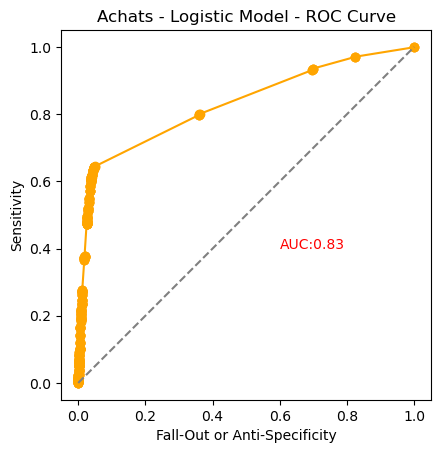

In [27]:
plt.figure()
plt.axes().set_aspect('equal')

plt.plot(fpr,tpr,'o-',color='orange')
plt.plot([0,1],[0,1],'--',color='grey')

plt.title('Achats - Logistic Model - ROC Curve')
plt.xlabel('Fall-Out or Anti-Specificity')
plt.ylabel('Sensitivity')

plt.text(0.6,0.4,"AUC:{0:.2f}".format(roc_auc),color='red')

plt.show()

In [28]:
model.coef_

array([[ 0.61120407,  1.56293669,  1.25649391,  1.26739139,  1.68779457,
         0.73543681, -0.23427367,  2.73892372, -0.5392297 ]])

In [29]:
X.columns

Index(['cough', 'fever', 'sore_throat', 'shortness_of_breath', 'head_ache',
       'age_60_and_above', 'gender', 'test_indication_c', 'test_indication_a'],
      dtype='object')